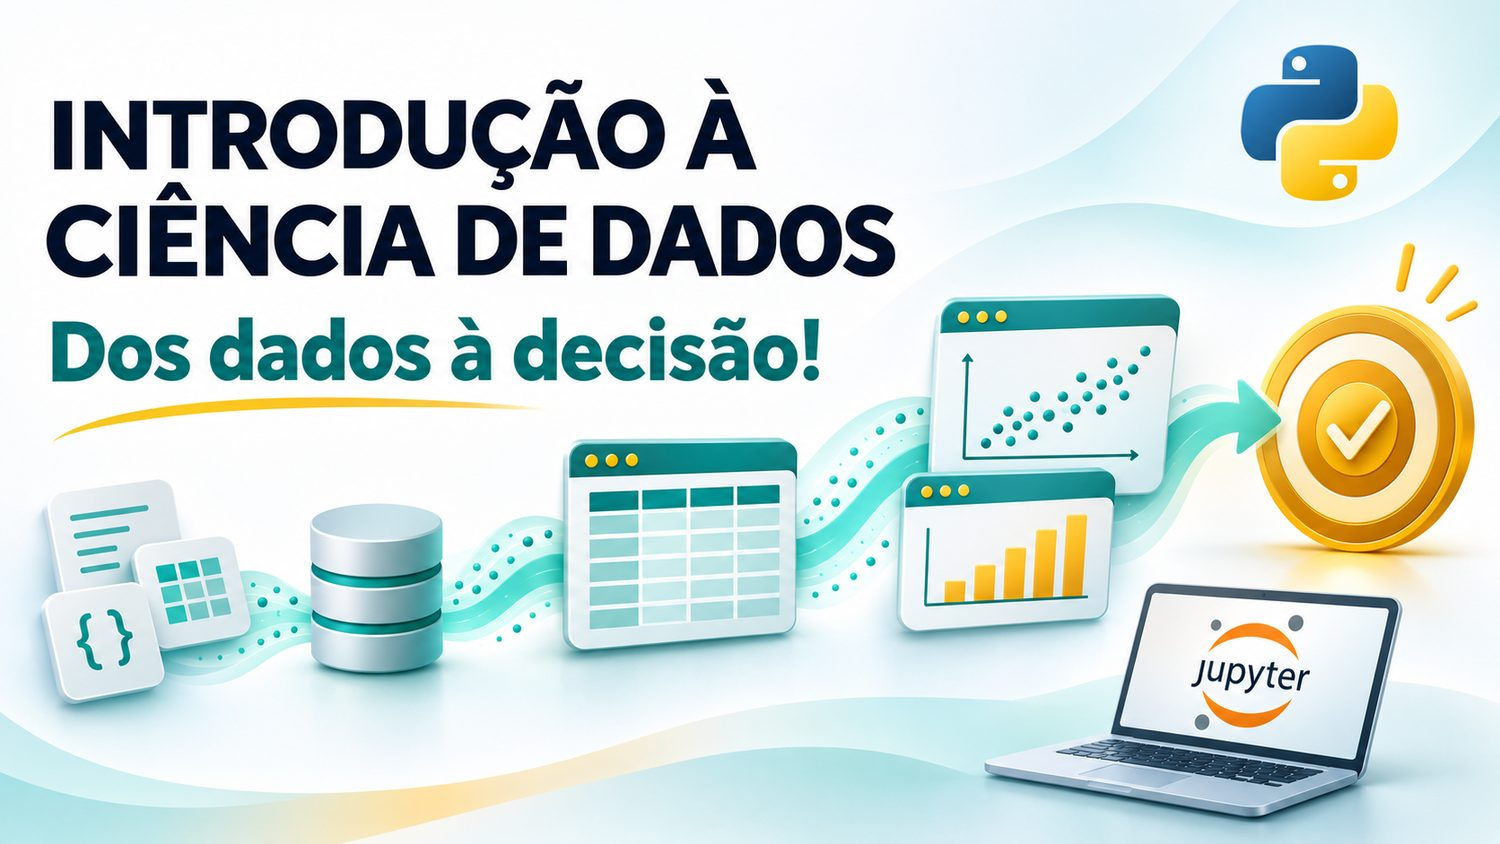

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_7_aprendizagem_nao_supervisionada/04_PCA.ipynb)

# Capítulo 4 – Reduzir dimensões: análise de componentes principais

Os utilizadores da aplicação são descritos por oito colunas. Não se desenha um gráfico com oito eixos, e no módulo 6 vimos que as distâncias perdem sentido quando há muitos atributos. A **análise de componentes principais** (PCA, de *principal component analysis*) resume muitas colunas em poucas, perdendo o mínimo de informação. Este capítulo constrói a PCA de raiz e mostra como ler o que ela devolve.

> **Objetivos:** explicar porque colunas correlacionadas permitem reduzir a dimensão; ver uma componente principal como a direção de maior variância; implementar a PCA em NumPy; interpretar a variância explicada e escolher o número de componentes; ler os pesos de cada componente; projetar e reconstruir os dados; conhecer os cuidados a ter.

**Pré-requisitos:** capítulos 1 a 3, e o capítulo 5 do módulo 3 (correlação). Não é preciso saber álgebra linear: as duas operações necessárias são explicadas no texto.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_utilizadores(n=3000, semente=53, com_perfil=False):
    """Gera utilizadores de uma aplicação fictícia de aprendizagem de línguas (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    perfil = rng.choice(4, n, p=[0.34, 0.22, 0.30, 0.14])
    # por perfil: sessões por semana, minutos por sessão, dias seguidos, % à noite, exercícios de fala, % de erros
    centros = np.array([[9.5, 6.0, 38, 30, 2.0, 22],
                        [2.2, 34.0, 3, 55, 6.0, 17],
                        [1.3, 7.0, 1, 45, 0.6, 31],
                        [7.5, 27.0, 55, 40, 14.0, 12]])
    desvios = np.array([[2.2, 1.8, 22, 16, 1.6, 6], [0.8, 8.0, 2.5, 18, 3.0, 5], [0.7, 3.0, 1.2, 20, 0.7, 8], [2.0, 7.0, 30, 17, 5.0, 4]])
    v = rng.normal(centros[perfil], desvios[perfil])
    sessoes = v[:, 0].clip(0.2, 21).round(1)
    minutos = v[:, 1].clip(2, 70).round(1)
    licoes = (sessoes * minutos / 5.5 * rng.normal(1, 0.12, n)).clip(0.2).round(1)
    tabela = pd.DataFrame({"sessoes_semana": sessoes, "minutos_sessao": minutos, "licoes_semana": licoes,
                           "dias_seguidos": v[:, 2].clip(0, 200).round(), "pct_noite": v[:, 3].clip(0, 100).round(),
                           "exercicios_fala": v[:, 4].clip(0, 40).round(1), "pct_erros": v[:, 5].clip(2, 60).round(1),
                           "meses_na_app": rng.gamma(1.8, 5, n).clip(0.5, 48).round(1)})
    tabela["premium"] = rng.random(n) < np.array([0.12, 0.25, 0.03, 0.55])[perfil]
    if com_perfil:                                   # só para verificação: num caso real esta coluna não existe
        tabela["perfil_verdadeiro"] = perfil
    return tabela


utilizadores = gerar_utilizadores()
utilizadores.head()

,sessoes_semana,minutos_sessao,licoes_semana,dias_seguidos,pct_noite,exercicios_fala,pct_erros,meses_na_app,premium
0,10.3,9.2,11.2,25.0,49.0,0.9,15.8,17.9,False
1,1.4,7.0,1.7,0.0,62.0,0.0,32.3,3.2,False
2,9.5,5.1,8.7,52.0,58.0,3.7,28.6,22.9,False
3,2.7,25.2,13.0,29.0,52.0,13.3,13.1,8.4,False
4,11.7,8.2,15.5,39.0,14.0,0.0,21.7,16.4,False


## Porque é possível resumir

Se as oito colunas fossem independentes umas das outras, cada uma traria informação que nenhuma outra tem, e não haveria nada a resumir. Mas não são.

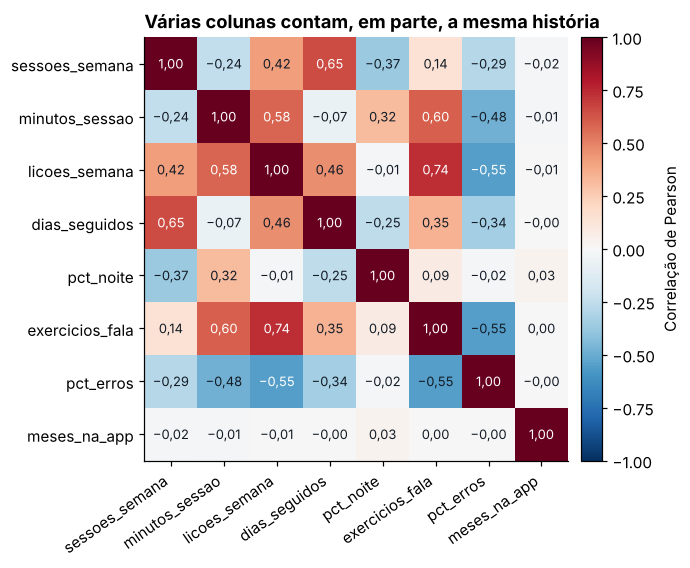

In [3]:
numericas = [c for c in utilizadores.columns if c != "premium"]
correlacoes = utilizadores[numericas].corr()

fig, ax = plt.subplots(figsize=(7.4, 5))
imagem = ax.imshow(correlacoes, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        valor = correlacoes.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}".replace(".", ",").replace("-", "−"), ha="center", va="center", fontsize=8.5, color="white" if abs(valor) > 0.55 else TINTA)
ax.set_xticks(range(len(numericas)), numericas, rotation=35, ha="right")
ax.set_yticks(range(len(numericas)), numericas)
ax.grid(False)
fig.colorbar(imagem, ax=ax, label="Correlação de Pearson", pad=0.02)
ax.set_title("Várias colunas contam, em parte, a mesma história")
plt.show()

Quem faz muitas sessões tem sequências longas; quem faz sessões longas conclui mais lições e faz mais exercícios de fala; quem pratica mais erra menos. Estas colunas **repetem informação**. Só `meses_na_app` não se relaciona com nenhuma outra.

A PCA aproveita esta redundância: procura um pequeno número de **colunas novas**, combinações das originais, que guardem quase toda a variação dos dados.

## A ideia, em duas dimensões

Começamos com duas colunas correlacionadas, normalizadas: as sessões por semana e os dias seguidos.

Imagina que só podes guardar **um número** por utilizador. Qual? Podias guardar só as sessões, e perdias os dias seguidos. Melhor: traçar uma **reta** através da nuvem e guardar a posição de cada utilizador ao longo dela. A melhor reta é a que mantém os pontos o mais espalhados possível, ou seja, a direção de **maior variância**.

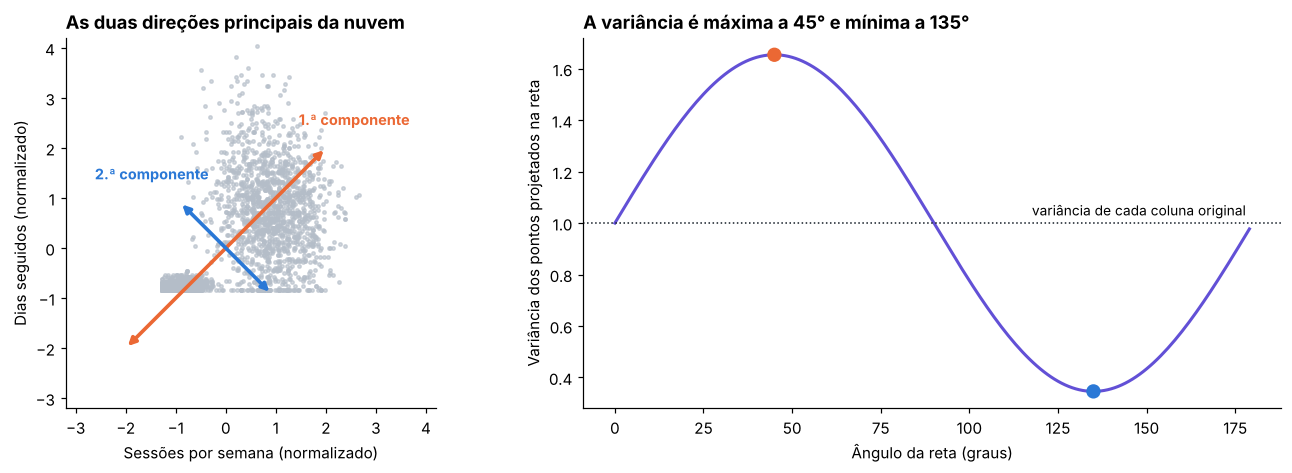

In [4]:
par = ["sessoes_semana", "dias_seguidos"]
P = utilizadores[par].to_numpy()
P = (P - P.mean(axis=0)) / P.std(axis=0)


def variancia_na_direcao(P, angulo):
    """Variância dos pontos projetados numa reta com o ângulo dado (em graus)."""
    direcao = np.array([np.cos(np.radians(angulo)), np.sin(np.radians(angulo))])
    return float((P @ direcao).var())


angulos = np.arange(0, 180)
variancias = np.array([variancia_na_direcao(P, a) for a in angulos])
melhor = int(angulos[variancias.argmax()])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
ax1.scatter(P[:, 0], P[:, 1], s=5, color=CINZA, alpha=0.6)
for angulo, cor, rotulo in [(melhor, LARANJA, "1.ª componente"), (melhor + 90, AZUL, "2.ª componente")]:
    d = np.array([np.cos(np.radians(angulo)), np.sin(np.radians(angulo))])
    comprimento = 2.2 * np.sqrt(variancia_na_direcao(P, angulo))
    ax1.annotate("", d * comprimento, -d * comprimento, arrowprops={"arrowstyle": "<|-|>", "color": cor, "lw": 2.4})
    ax1.text(*(d * (comprimento + 0.8)), rotulo, color=cor, fontweight="bold", ha="center", va="center", fontsize=9.5)
ax1.set_xlim(-3.2, 4.2)
ax1.set_ylim(-3.2, 4.2)
ax1.set_aspect("equal")
ax1.set_xlabel("Sessões por semana (normalizado)")
ax1.set_ylabel("Dias seguidos (normalizado)")
ax1.set_title("As duas direções principais da nuvem")
ax2.plot(angulos, variancias, color=VIOLETA, lw=2)
ax2.scatter([melhor, (melhor + 90) % 180], [variancias.max(), variancias.min()], color=[LARANJA, AZUL], s=70, zorder=3)
ax2.axhline(1, color=TINTA, ls=":", lw=1)
ax2.text(178, 1.03, "variância de cada coluna original", ha="right", fontsize=9)
ax2.set_xlabel("Ângulo da reta (graus)")
ax2.set_ylabel("Variância dos pontos projetados na reta")
ax2.set_title(f"A variância é máxima a {melhor}° e mínima a {(melhor + 90) % 180}°")
plt.tight_layout()
plt.show()

À direita, a variância dos pontos projetados em cada reta possível. Projetar num dos eixos originais (0° ou 90°) guarda uma variância de 1, a de cada coluna normalizada. A 45°, guarda-se bastante mais: essa direção é a **primeira componente principal**.

A **segunda componente** é a direção perpendicular à primeira. Nela a variância é mínima: é o que sobra depois de retirar a primeira.

As duas componentes juntas guardam **toda** a variância (1 + 1 = 2). Apenas a repartiram de outra maneira: quase tudo na primeira, pouco na segunda. Se ficarmos só com a primeira, guardamos a maior parte da informação num único número.

In [5]:
v1, v2 = variancias.max(), variancias.min()
print(f"Variância na 1.ª componente: {v1:.2f} ({v1 / (v1 + v2):.0%} do total)")
print(f"Variância na 2.ª componente: {v2:.2f} ({v2 / (v1 + v2):.0%} do total)")
print(f"Correlação entre as duas colunas: {np.corrcoef(P.T)[0, 1]:.2f}")

Variância na 1.ª componente: 1.65 (83% do total)
Variância na 2.ª componente: 0.35 (17% do total)
Correlação entre as duas colunas: 0.65


Com duas colunas normalizadas, as variâncias das componentes são 1 + r e 1 − r, em que r é a correlação. Quanto mais correlacionadas as colunas, mais a primeira componente concentra, e mais barato fica deitar fora a segunda.

## A PCA de raiz, com as oito colunas

Com oito colunas não se pode experimentar todos os ângulos. Felizmente há um cálculo direto, em quatro passos.

1. **Normalizar** as colunas (média 0, desvio padrão 1).
2. Calcular a **matriz de covariâncias**: uma tabela 8 × 8 que diz como cada par de colunas varia em conjunto. Com colunas normalizadas, é a matriz de correlações que desenhámos acima.
3. Calcular os **vetores e valores próprios** dessa matriz. É uma operação de álgebra linear que o NumPy faz numa linha. O que importa é o significado do resultado:
   - cada **vetor próprio** é uma direção: uma componente principal;
   - o **valor próprio** correspondente é a variância dos dados nessa direção.
4. **Ordenar** as componentes da maior variância para a menor e **projetar** os dados nelas.

In [6]:
X = utilizadores[numericas].to_numpy()
Z = (X - X.mean(axis=0)) / X.std(axis=0)                       # 1. normalizar

covariancias = (Z.T @ Z) / len(Z)                              # 2. matriz de covariâncias (8 × 8)
valores, vetores = np.linalg.eigh(covariancias)                # 3. valores e vetores próprios
ordem = np.argsort(valores)[::-1]                              # 4. ordenar da maior variância para a menor
valores, vetores = valores[ordem], vetores[:, ordem]
componentes = Z @ vetores                                      #    projetar: as coordenadas novas de cada utilizador

print("Variância de cada componente:", valores.round(2))
print("Soma das variâncias:", valores.sum().round(2), "(igual ao número de colunas)")
print("Variância das coordenadas novas:", componentes.var(axis=0).round(2))

Variância de cada componente: [3.07 1.97 1.   0.69 0.52 0.37 0.27 0.13]
Soma das variâncias: 8.0 (igual ao número de colunas)
Variância das coordenadas novas: [3.07 1.97 1.   0.69 0.52 0.37 0.27 0.13]


O símbolo `@` é o produto de matrizes. `Z @ vetores` calcula, para cada utilizador, uma **soma ponderada** das suas oito colunas, uma vez para cada componente: os pesos estão nas colunas de `vetores`.

A soma das variâncias é 8, uma por coluna normalizada: nada se perdeu, foi só redistribuído. E as coordenadas novas têm uma propriedade útil:

In [7]:
print("Maior correlação (em valor absoluto) entre duas componentes diferentes:",
      f"{np.abs(np.corrcoef(componentes.T) - np.eye(8)).max():.1e}")

Maior correlação (em valor absoluto) entre duas componentes diferentes: 1.6e-15


As componentes **não estão correlacionadas** entre si. Cada uma traz informação que as anteriores não têm. É o contrário das colunas originais.

Comparamos com o scikit-learn:

In [8]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca = PCA().fit(Z)
print("scikit-learn, variância de cada componente:", pca.explained_variance_.round(2))
iguais = np.allclose(np.abs(pca.transform(Z)), np.abs(componentes), atol=1e-6)
print("Coordenadas iguais às nossas, a menos do sinal:", iguais)

scikit-learn, variância de cada componente: [3.07 1.97 1.   0.69 0.52 0.37 0.27 0.13]
Coordenadas iguais às nossas, a menos do sinal: True


Os resultados coincidem. (O scikit-learn divide por n − 1 em vez de n, uma diferença que com 3 000 utilizadores só aparece depois da terceira casa decimal.) O **sinal** de cada componente é arbitrário: uma direção e a sua oposta são a mesma reta. Duas implementações podem devolver componentes simétricas, e nenhuma está errada.

## Quantas componentes guardar?

A **variância explicada** de uma componente é a sua parte na variância total.

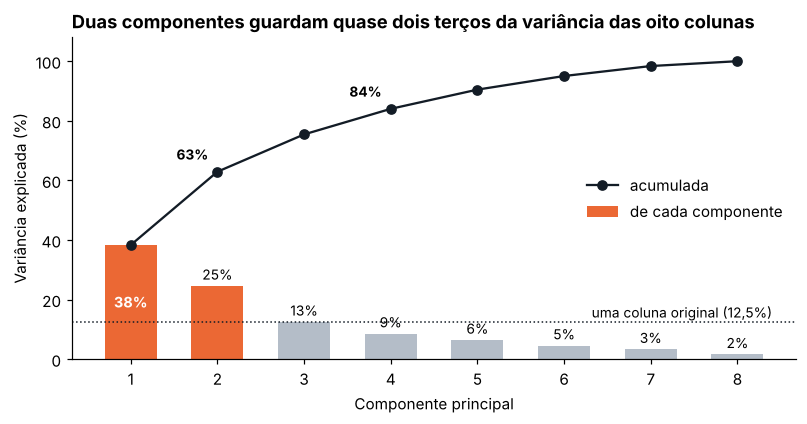

In [9]:
explicada = pd.Series(valores / valores.sum(), index=range(1, 9))
acumulada = explicada.cumsum()

fig, ax = plt.subplots(figsize=(8.5, 3.8))
barras = ax.bar(explicada.index, explicada * 100, color=[LARANJA if i <= 2 else CINZA for i in explicada.index], width=0.6, label="de cada componente")
ax.bar_label(barras, labels=[""] + [f"{v:.0%}" for v in explicada[1:]], padding=2, fontsize=9)
ax.text(1, explicada[1] * 50, f"{explicada[1]:.0%}", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
ax.plot(acumulada.index, acumulada * 100, "o-", color=TINTA, label="acumulada")
for i in [2, 4]:
    ax.annotate(f"{acumulada[i]:.0%}", (i, acumulada[i] * 100), textcoords="offset points", xytext=(-6, 8), ha="right", fontsize=9, fontweight="bold")
ax.axhline(100 / 8, color=TINTA, ls=":", lw=1)
ax.text(8.4, 100 / 8 + 1.5, "uma coluna original (12,5%)", ha="right", fontsize=9)
ax.set_xlabel("Componente principal")
ax.set_ylabel("Variância explicada (%)")
ax.set_ylim(0, 108)
ax.set_title("Duas componentes guardam quase dois terços da variância das oito colunas")
ax.legend(frameon=False, loc="center right")
plt.show()

A primeira componente, sozinha, guarda três vezes mais do que uma coluna original. Com duas, chega-se a quase dois terços; com quatro, a mais de 80%.

Não há uma regra única para escolher quantas guardar. Depende do objetivo.

| Objetivo | Critério habitual |
| --- | --- |
| **Visualizar** | Duas componentes (ou três), sabendo quanto se perde |
| **Resumir** para outro modelo | As suficientes para 80% a 95% da variância |
| **Interpretar** | As que explicam mais do que uma coluna original (linha pontilhada) e que se conseguem descrever |

## O que significa cada componente?

Uma componente é uma soma ponderada das colunas originais. Os **pesos** dizem que colunas contam, e em que sentido.

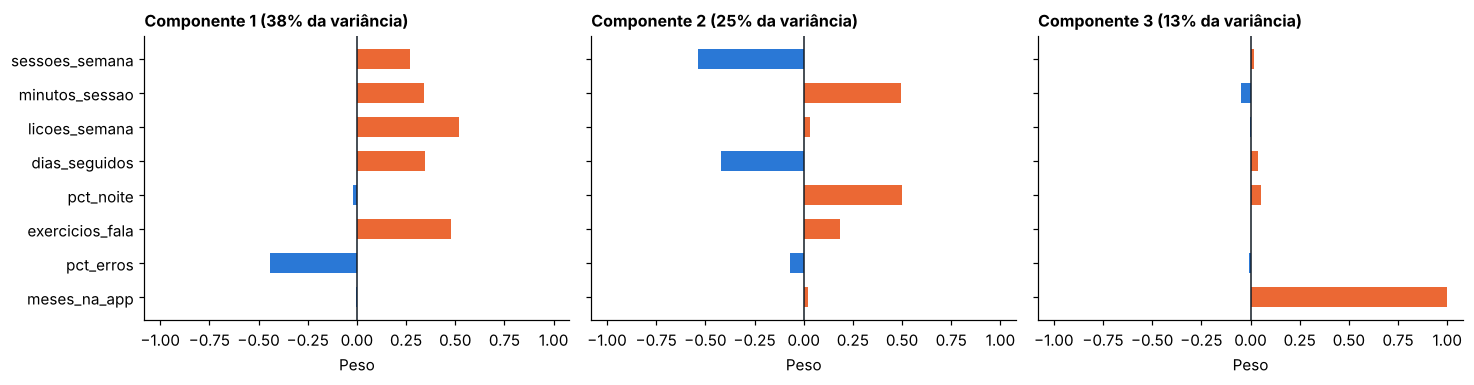

In [10]:
pesos = pd.DataFrame(vetores[:, :3], index=numericas, columns=["Componente 1", "Componente 2", "Componente 3"])
pesos = pesos * np.sign(pesos.loc[["licoes_semana", "minutos_sessao", "meses_na_app"]].to_numpy().diagonal())    # orientação escolhida para facilitar a leitura

fig, eixos = plt.subplots(1, 3, figsize=(13.5, 3.6), sharey=True)
for ax, coluna in zip(eixos, pesos.columns):
    barras = ax.barh(pesos.index, pesos[coluna], color=[LARANJA if v > 0 else AZUL for v in pesos[coluna]], height=0.6)
    ax.axvline(0, color=TINTA, lw=1)
    ax.set_xlim(-1.08, 1.08)
    ax.set_title(f"{coluna} ({explicada[int(coluna[-1])]:.0%} da variância)", fontsize=10.5)
    ax.set_xlabel("Peso")
eixos[0].invert_yaxis()
plt.tight_layout()
plt.show()

Lê-se cada painel procurando as barras mais compridas.

- **Componente 1:** pesos positivos nas lições, nos dias seguidos, nos exercícios de fala e nas sessões; negativo nos erros. Mede a **intensidade de utilização**. Um valor alto é um utilizador muito ativo e que erra pouco.
- **Componente 2:** pesos positivos nos minutos por sessão e na percentagem de sessões à noite, e negativos nas sessões por semana e nos dias seguidos. Opõe **sessões longas e raras, à noite,** a **sessões curtas e frequentes**. Mede o **estilo** de utilização, e não a quantidade.
- **Componente 3:** quase só `meses_na_app`. É a antiguidade, que não se relaciona com mais nada e por isso fica com uma componente só para si.

Dar nome às componentes, como aos grupos, é a parte que exige conhecimento do problema. Nem sempre é possível: muitas vezes as componentes misturam colunas de forma que não se deixa descrever numa frase. Nesse caso servem para comprimir, e não para explicar.

## Ver os utilizadores em duas dimensões

Com duas componentes podemos, finalmente, desenhar os oito atributos num plano. Pintamos cada utilizador com o grupo que o K-Means lhe atribuiu no capítulo 1 (usando as oito colunas).

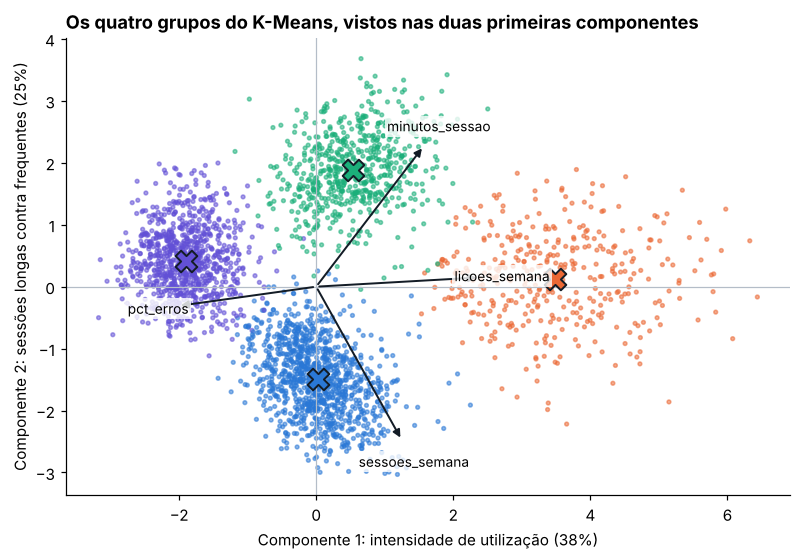

In [11]:
from sklearn.cluster import KMeans

CORES = [AZUL, LARANJA, VERDE, VIOLETA]
grupos = KMeans(4, n_init=10, random_state=0).fit_predict(Z)
coordenadas = Z @ pesos.to_numpy()[:, :2]

fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.scatter(coordenadas[:, 0], coordenadas[:, 1], s=6, color=[CORES[g] for g in grupos], alpha=0.55)
for g in range(4):
    centro = coordenadas[grupos == g].mean(axis=0)
    ax.scatter(*centro, marker="X", s=200, color=CORES[g], edgecolor=TINTA, linewidth=1.3, zorder=3)
for nome in ["sessoes_semana", "minutos_sessao", "licoes_semana", "pct_erros"]:
    ponta = pesos.loc[nome].to_numpy()[:2] * 4.6
    ax.annotate("", ponta, (0, 0), arrowprops={"arrowstyle": "-|>", "color": TINTA, "lw": 1.3})
    ax.text(*(ponta * 1.14), nome, fontsize=9, ha="center", va="center", bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1.5})
ax.axhline(0, color=CINZA, lw=0.8)
ax.axvline(0, color=CINZA, lw=0.8)
ax.set_xlabel(f"Componente 1: intensidade de utilização ({explicada[1]:.0%})")
ax.set_ylabel(f"Componente 2: sessões longas contra frequentes ({explicada[2]:.0%})")
ax.set_title("Os quatro grupos do K-Means, vistos nas duas primeiras componentes")
plt.show()

Os quatro grupos aparecem como quatro nuvens distintas. A posição de cada uma lê-se pelos eixos: à direita os utilizadores mais intensos, em cima os de sessões longas.

As **setas** mostram para onde aponta cada coluna original neste plano. Uma seta comprida é uma coluna bem representada pelas duas componentes; setas na mesma direção são colunas correlacionadas; setas opostas, colunas que variam em sentido contrário. A este tipo de gráfico chama-se **biplot**.

Um aviso: este plano mostra cerca de dois terços da variância. Dois pontos **afastados** aqui estão afastados nos dados originais, mas dois pontos **próximos** podem diferir nas componentes que não se veem. O gráfico serve para ganhar intuição; o agrupamento foi feito com as oito colunas.

## Reconstruir: quanto se perdeu?

Com as coordenadas nas componentes pode fazer-se o caminho inverso e obter uma **aproximação** dos dados originais. Com todas as componentes, a reconstrução é exata; com menos, perde-se o que as componentes excluídas guardavam.

In [12]:
def reconstruir(Z, vetores, n):
    """Projeta nas n primeiras componentes e volta ao espaço original."""
    V = vetores[:, :n]
    return (Z @ V) @ V.T


perdas = pd.Series({n: np.mean((Z - reconstruir(Z, vetores, n)) ** 2) for n in range(1, 9)})
um = 0                                                          # o primeiro utilizador
tabela = pd.DataFrame({"original": X[um]}, index=numericas)
for n in [2, 4, 8]:
    tabela[f"com {n} componentes"] = reconstruir(Z, vetores, n)[um] * X.std(axis=0) + X.mean(axis=0)     # de volta às unidades originais
print(tabela.round(1))
print("\nErro quadrático médio da reconstrução:", {n: round(float(v), 2) for n, v in perdas.items()})
print("Variância não explicada:               ", {n: round(float(1 - acumulada[n]), 2) for n in range(1, 9)})

                 original  com 2 componentes  com 4 componentes  \
sessoes_semana       10.3                7.2                8.0   
minutos_sessao        9.2               10.9                8.0   
licoes_semana        11.2               13.0               12.5   
dias_seguidos        25.0               33.5               42.0   
pct_noite            49.0               33.8               47.3   
exercicios_fala       0.9                3.8                3.5   
pct_erros            15.8               22.2               22.4   
meses_na_app         17.9                8.8               17.8   

                 com 8 componentes  
sessoes_semana                10.3  
minutos_sessao                 9.2  
licoes_semana                 11.2  
dias_seguidos                 25.0  
pct_noite                     49.0  
exercicios_fala                0.9  
pct_erros                     15.8  
meses_na_app                  17.9  

Erro quadrático médio da reconstrução: {1: 0.62, 2: 0.37, 3: 0

Com duas componentes, a reconstrução dá a ideia geral deste utilizador (muitas sessões curtas, poucos exercícios de fala), com erros visíveis. A antiguidade, que as duas primeiras componentes ignoram, fica simplesmente na média geral. Com quatro, a antiguidade e a percentagem à noite já são recuperadas quase na perfeição. Com as oito, a reconstrução é exata.

As duas últimas linhas são iguais: **o erro de reconstrução é exatamente a variância não explicada**. É isso que quer dizer «guardar 80% da variância».

## Cuidados

| Cuidado | Porquê |
| --- | --- |
| **Normalizar antes** | A PCA procura variância. Sem normalização, a coluna com números maiores fica com a primeira componente só por causa da unidade (exercício 2) |
| **Só capta relações lineares** | Cada componente é uma soma ponderada. Estruturas curvas não são resumidas |
| **Variância não é importância** | A componente que mais varia pode não ser a que interessa para prever um alvo. A PCA não vê o alvo |
| **Sensível a valores extremos** | Um ponto muito afastado cria variância e puxa as componentes para si |
| **As componentes podem não ter nome** | Ganha-se compressão e perde-se a leitura direta das colunas |
| **Aprende com os dados** | Num modelo supervisionado, a PCA vai dentro do pipeline e ajusta-se só com o treino (módulo 6, capítulo 6) |

Para visualizar dados com estrutura não linear existem outros métodos, como o t-SNE e o UMAP. Produzem mapas mais expressivos, mas as distâncias e os eixos desses mapas não têm interpretação direta, ao contrário dos da PCA.

## Para que serve, em resumo

| Uso | Exemplo |
| --- | --- |
| **Visualizar** dados com muitas colunas | O mapa dos utilizadores deste capítulo |
| **Resumir** colunas redundantes num índice | Um «índice de intensidade» em vez de cinco colunas |
| **Reduzir a dimensão** antes de um método baseado em distâncias | KNN ou K-Means com dezenas de colunas correlacionadas |
| **Retirar ruído** | Guardar as componentes principais e deitar fora as de variância mínima |
| **Eliminar a correlação** entre atributos | Antes de modelos que são instáveis com colunas muito correlacionadas |

## Exercícios

### `Exercício 1` – Duas colunas, à mão

Duas colunas normalizadas têm uma correlação de 0,8. Qual é a variância de cada uma das duas componentes principais? Que percentagem da variância total guarda a primeira? E se a correlação fosse 0?

<details>
<summary><b>Ver uma solução possível</b></summary>

As variâncias são 1 + r e 1 − r: **1,8** e **0,2**. A primeira guarda 1,8 ÷ 2 = **90%**.

Com correlação 0, as duas componentes têm variância 1: cada uma guarda 50%, e não há direção melhor do que outra. Sem correlação, a PCA não tem nada para resumir.

</details>

### `Exercício 2` – Sem normalizar

Aplica a PCA às oito colunas **sem normalizar** (apenas centradas, que é o que o `PCA` do scikit-learn faz sozinho). Que percentagem da variância fica na primeira componente? Que colunas têm os maiores pesos? Porquê?

In [13]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
sem = PCA().fit(utilizadores[numericas])
print("Variância explicada:", sem.explained_variance_ratio_.round(2))
print(pd.Series(sem.components_[0], index=numericas).round(2).sort_values(key=abs, ascending=False))
print(utilizadores[numericas].var().round(0).sort_values(ascending=False))
```

A primeira componente fica com mais de metade da variância e é quase só `dias_seguidos`, a coluna com a maior variância nas unidades originais. A PCA procura variância, e sem normalização encontra-a na coluna que tem os números maiores. Se os dias fossem medidos em semanas, o resultado mudava. Com colunas em unidades diferentes, normalizar é obrigatório.

</details>

### `Exercício 3` – Um índice de intensidade

Usa a primeira componente como «índice de intensidade» de cada utilizador. Compara a média do índice entre utilizadores premium e não premium, e calcula a taxa de premium em cada quartil do índice.

In [14]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
indice = pd.Series(coordenadas[:, 0], index=utilizadores.index)
print(indice.groupby(utilizadores["premium"]).mean().round(2))
print(utilizadores["premium"].groupby(pd.qcut(indice, 4, labels=["1.º quartil", "2.º", "3.º", "4.º quartil"]), observed=True).mean().round(2))
```

Os utilizadores premium têm um índice claramente mais alto, e a taxa de premium cresce de quartil para quartil. Um só número, construído sem olhar para a coluna `premium`, resume o suficiente das oito colunas para ordenar os utilizadores por propensão a pagar. É uma associação: não diz se a intensidade leva à subscrição ou se quem subscreve passa a usar mais.

</details>

### `Exercício 4` – Agrupar nas componentes

Aplica o K-Means (k = 4) às duas primeiras componentes, em vez das oito colunas. Compara os grupos com os do K-Means original (`grupos`), usando o índice de Rand ajustado. Experimenta também com quatro componentes. O que se ganha e o que se perde?

In [15]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.metrics import adjusted_rand_score, silhouette_score

for n in [2, 4, 8]:
    C = componentes[:, :n]
    g = KMeans(4, n_init=10, random_state=0).fit_predict(C)
    print(f"{n} componentes: concordância com o agrupamento original {adjusted_rand_score(grupos, g):.2f} | silhueta {silhouette_score(C, g):.2f}")
```

Com duas componentes, o agrupamento é muito parecido com o original e a silhueta é mais alta: as componentes excluídas continham sobretudo variação que não distingue os grupos (a antiguidade, a hora do dia). Ganha-se um agrupamento mais nítido e que se pode desenhar. Perde-se a possibilidade de os grupos usarem a informação excluída, e as silhuetas calculadas em espaços diferentes não são comparáveis (capítulo 2). Com as oito componentes o resultado é igual ao original: a PCA completa só roda os eixos, e as distâncias não mudam.

</details>

## Verifica o que aprendeste

- [ ] Sei porque a correlação entre colunas permite reduzir a dimensão.
- [ ] Sei explicar uma componente principal como direção de maior variância.
- [ ] Sei os quatro passos da PCA e implementá-los em NumPy.
- [ ] Sei ler a variância explicada e escolher o número de componentes.
- [ ] Sei interpretar os pesos de uma componente.
- [ ] Sei ler um mapa dos dados nas duas primeiras componentes, e os seus limites.
- [ ] Sei porque é preciso normalizar antes da PCA.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/decomposition.html#pca
- https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
- https://en.wikipedia.org/wiki/Principal_component_analysis